# Ценовое позиционирование: анализ витрин мониторинга

Ноутбук работает поверх хранилища, которое заполняет пайплайн. Перед запуском загрузите историю за 14 дней:

```bash
python -m src.pipeline --start 2026-10-07 --end 2026-10-20
```

Данные синтетические: три площадки отдаёт встроенный имитатор API, своя матрица (76 SKU напитков) повторяет структуру выгрузки из 1С.

План:
1. Объём и качество загрузки
2. Качество матчинга с нашей матрицей
3. Ценовой индекс и позиционирование на последнюю дату
4. Алерты и рекомендованные цены
5. Динамика цен за две недели

In [1]:
import sys
from datetime import date, timedelta
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config
from src.evaluate import evaluate_matching, matching_metrics

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

INK, ACCENT, WARM, GREY = "#141A2E", "#2C52C4", "#B5631A", "#9AA3B5"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E6EC", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

cfg = load_config()
con = duckdb.connect(cfg["paths"]["db"], read_only=True)
LAST = con.execute("SELECT MAX(snapshot_date) FROM core.own_prices").fetchone()[0]
DAYS = con.execute("SELECT COUNT(DISTINCT snapshot_date) FROM core.own_prices").fetchone()[0]
print(f"В хранилище {DAYS} дней, последняя дата {LAST}")

В хранилище 14 дней, последняя дата 2026-10-20


## 1. Объём и качество загрузки

Журнал `core.load_log` пишет пайплайн: сколько позиций пришло с площадки, сколько дублей и отбраковки, сколько сопоставлено с нашей матрицей, сколько было повторов запросов после временных ошибок API.

In [2]:
load = con.execute("""
    SELECT source,
           SUM(n_raw) AS получено, SUM(n_duplicates) AS дублей, SUM(n_rejected) AS отклонено,
           SUM(n_matched) AS сопоставлено, SUM(n_requests) AS запросов, SUM(n_retries) AS повторов,
           ROUND(AVG(seconds), 2) AS сек_на_источник
    FROM core.load_log GROUP BY source ORDER BY source
""").df()
load["доля_сопоставленных"] = (load["сопоставлено"] / (load["получено"] - load["дублей"] - load["отклонено"])).round(3)
rejects = con.execute("SELECT reason AS причина, COUNT(*) AS позиций FROM staging.rejects GROUP BY 1").df()
display(load)
display(rejects)

,source,получено,дублей,отклонено,сопоставлено,запросов,повторов,сек_на_источник,доля_сопоставленных
0,market_a,1246.0,0.0,0.0,1064.0,59.0,3.0,0.13,0.854
1,market_b,1036.0,0.0,19.0,808.0,48.0,6.0,0.11,0.794
2,market_c,1190.0,56.0,25.0,930.0,42.0,0.0,0.11,0.839


,причина,позиций
0,нет цены,44


Несопоставленные позиции не ошибка: на площадках есть товары, которых нет в нашей матрице (другие бренды, новые вкусы, другие объёмы). Сколько из них отсеяно правильно, видно на разметке ниже.

## 2. Качество матчинга

Имитатор знает истинное соответствие предложения нашему SKU, пайплайн эту разметку не видит. Сравниваем два варианта:

* **базовый**: нечёткое сравнение названий без словаря брендов и без штрафа за маркеры вариантов;
* **итоговый**: плюс словарь латинских написаний брендов и штраф, если у предложения есть маркер варианта (zero, лайт), которого нет у нашего SKU.

Точность: доля верных среди сопоставленных. Полнота: доля найденных среди товаров нашей матрицы.

In [3]:
days = [LAST - timedelta(d) for d in range(DAYS)]
cfg_base = dict(cfg, matching={**cfg["matching"], "brand_aliases": {}, "variant_penalty": 1.0})

final = pd.concat([evaluate_matching(cfg, d) for d in days], ignore_index=True)
base = pd.concat([evaluate_matching(cfg_base, d) for d in days], ignore_index=True)
quality = pd.DataFrame([matching_metrics(base), matching_metrics(final)], index=["базовый", "итоговый"])
quality

,offers,precision,recall,false_matches,missed,foreign_rejected
базовый,3372,0.9808,0.9822,54,50,512
итоговый,3372,1.0000,0.9986,0,4,566


In [4]:
err = final[(final["sku_id"] != final["true_sku"]) & ~(final["sku_id"].isna() & final["true_sku"].isna())]
err[["source", "raw_name", "true_sku", "match_score", "match_method"]].drop_duplicates("raw_name")

,source,raw_name,true_sku,match_score,match_method
588,market_b,ГОРНАЯ ВЕРШИНА вода негза. 5000 мл,SKU-0031,0.690,ниже порога
1564,market_b,ГОРНАЯ ВЕРШИНА вода нгеаз. 1500 мл,SKU-0030,0.621,ниже порога
1778,market_b,ГОРНАЯ ВЕРШИНА вода нгеаз. 500 мл,SKU-0029,0.621,ниже порога
2769,market_b,ЭНЕРДЖИ МАКС энергетик оирг. 450 мл,SKU-0070,0.759,ниже порога


Оставшиеся пропуски: опечатки внутри сокращений («клсас.», «минре.»). Их выгоднее пропустить, чем понизить порог и получить ложные склейки. Как порог влияет на точность и полноту, видно на графике: считаем лучший кандидат для каждого предложения без порога и двигаем отсечку.

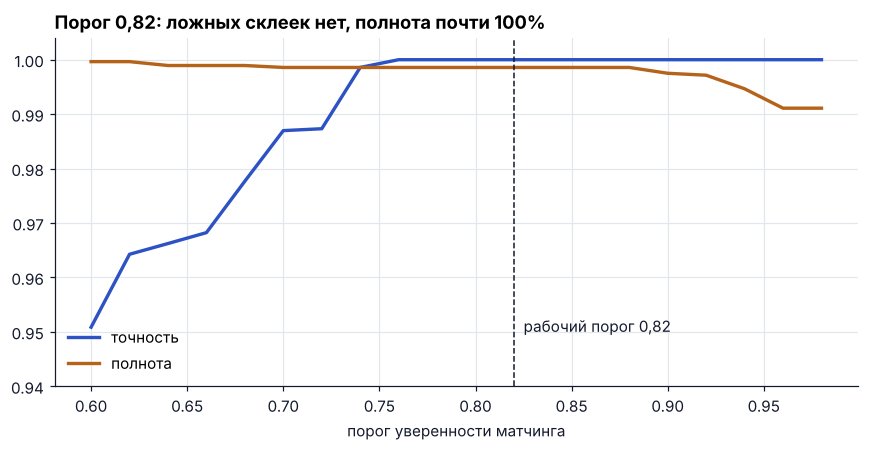

In [5]:
cfg_sweep = dict(cfg, matching={**cfg["matching"], "threshold": 0.0, "threshold_no_brand": 0.0})
raw = pd.concat([evaluate_matching(cfg_sweep, d) for d in days], ignore_index=True)
ours = raw["true_sku"].notna()
rows = []
for t in np.arange(0.60, 0.981, 0.02):
    pred = raw["sku_id"].notna() & (raw["match_score"] >= t)
    correct = pred & (raw["sku_id"] == raw["true_sku"])
    rows.append({"порог": round(t, 2), "точность": correct.sum() / max(pred.sum(), 1),
                 "полнота": correct.sum() / ours.sum()})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sweep["порог"], sweep["точность"], color=ACCENT, lw=2.2, label="точность")
ax.plot(sweep["порог"], sweep["полнота"], color=WARM, lw=2.2, label="полнота")
ax.axvline(cfg["matching"]["threshold"], color=INK, ls="--", lw=1)
ax.text(cfg["matching"]["threshold"] + 0.005, 0.95, "рабочий порог " + str(cfg["matching"]["threshold"]).replace(".", ","), color=INK)
ax.set_ylim(0.94, 1.004)
ax.set_xlabel("порог уверенности матчинга")
ax.set_title("Порог 0,82: ложных склеек нет, полнота почти 100%")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_matching_threshold.png")
plt.show()

## 3. Ценовой индекс на последнюю дату

Индекс = наша цена / медиана рынка × 100. Рынок по SKU: медиана лучших штучных предложений площадок в наличии. Коридор «в рынке» ±3%, алерт при отклонении больше 10%.

positioning
в рынке          37
дешевле рынка    28
дороже рынка     11
Медианный индекс: 100.0, SKU с рыночной ценой: 76


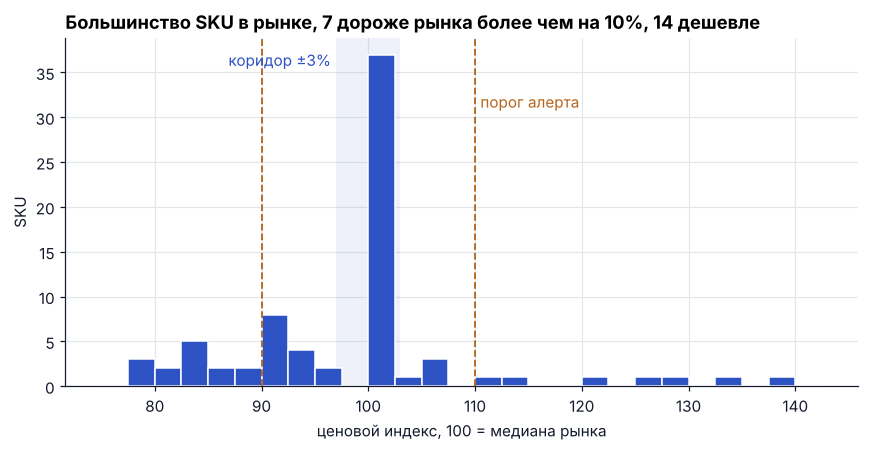

In [6]:
idx = con.execute("SELECT * FROM mart.price_index WHERE snapshot_date = ?", [LAST]).df()
idx["price_index"] = idx["price_index"].astype(float)
print(idx["positioning"].value_counts().to_string())
print(f"Медианный индекс: {idx['price_index'].median():.1f}, SKU с рыночной ценой: {len(idx)}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axvspan(97, 103, color=ACCENT, alpha=0.08, lw=0)
ax.hist(idx["price_index"], bins=np.arange(75, 145, 2.5), color=ACCENT, edgecolor="white")
for x in (90, 110):
    ax.axvline(x, color=WARM, ls="--", lw=1.2)
ax.text(96.5, ax.get_ylim()[1] * 0.92, "коридор ±3%", color=ACCENT, ha="right")
ax.text(110.5, ax.get_ylim()[1] * 0.80, "порог алерта", color=WARM)
n_exp = (idx["price_index"] > 110).sum()
n_cheap = (idx["price_index"] < 90).sum()
ax.set_title(f"Большинство SKU в рынке, {n_exp} дороже рынка более чем на 10%, {n_cheap} дешевле")
ax.set_xlabel("ценовой индекс, 100 = медиана рынка")
ax.set_ylabel("SKU")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_price_index_distribution.png")
plt.show()

,category,n_sku,median_index,share_cheaper,share_in_market,share_expensive
0,Вода,10,98.2,0.500,0.500,0.000
1,Газированные напитки,28,100.0,0.357,0.536,0.107
2,Энергетики,8,100.0,0.375,0.500,0.125
3,Соки и нектары,16,100.0,0.313,0.500,0.188
4,Холодный чай,8,100.0,0.375,0.375,0.250
5,Квас,6,100.1,0.333,0.333,0.333


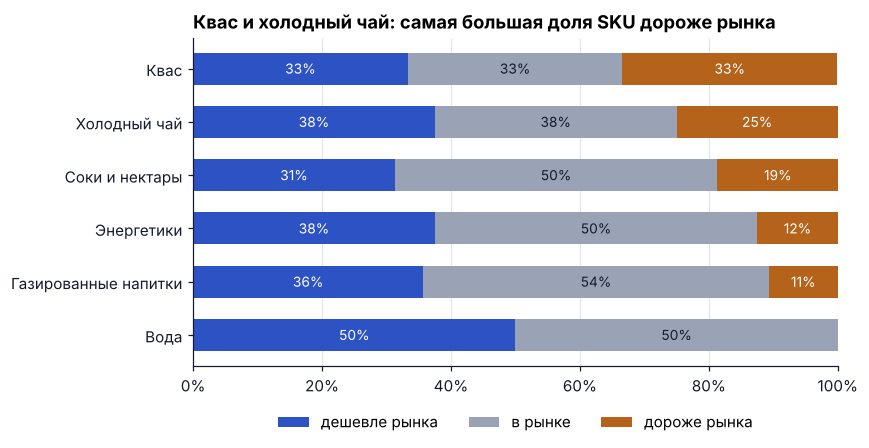

In [7]:
cat = con.execute("""SELECT category, n_sku, median_index, share_cheaper, share_in_market, share_expensive
                      FROM mart.category_index WHERE snapshot_date = ? ORDER BY share_expensive""", [LAST]).df()
display(cat)

fig, ax = plt.subplots(figsize=(8, 4.2))
left = np.zeros(len(cat))
for col, color, label in [("share_cheaper", ACCENT, "дешевле рынка"), ("share_in_market", GREY, "в рынке"),
                          ("share_expensive", WARM, "дороже рынка")]:
    vals = cat[col].astype(float).values
    ax.barh(cat["category"], vals, left=left, color=color, label=label, height=0.6)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.08:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color=INK if color == GREY else "white")
    left += vals
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_title("Квас и холодный чай: самая большая доля SKU дороже рынка")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_positioning_by_category.png")
plt.show()

## 4. Алерты и рекомендованные цены

Рекомендация: медиана рынка, но не ниже цены, при которой маржа остаётся не меньше 25%. В Excel-отчёте цена округляется до десятков с той же защитой минимальной маржи.

In [8]:
from src.report import shelf_price

alerts = con.execute("SELECT * FROM mart.price_alerts WHERE snapshot_date = ? ORDER BY ABS(deviation) DESC", [LAST]).df()
for c in ["own_price", "market_median", "purchase_price", "recommended_price", "min_price_for_margin", "deviation"]:
    alerts[c] = alerts[c].astype(float)
alerts["рекомендованная"] = [shelf_price(r, f, o) for r, f, o in
                             zip(alerts["recommended_price"], alerts["min_price_for_margin"], alerts["own_price"])]
print(alerts["alert_type"].value_counts().to_string())
alerts[["name", "own_price", "market_median", "deviation", "alert_type", "рекомендованная", "note"]].head(10)

alert_type
дешевле рынка    14
дороже рынка      7


,name,own_price,market_median,deviation,alert_type,рекомендованная,note
0,Лимонад Крем-сода Лимонадная артель 1 л,109.0,78.995,0.380,дороже рынка,90.0,ограничено минимальной маржой
1,Сок мультифрукт Фруктовый край 1 л,119.0,88.990,0.337,дороже рынка,119.0,ограничено минимальной маржой
2,Чай малина Чайная долина 1 л,89.0,69.000,0.290,дороже рынка,80.0,ограничено минимальной маржой
3,"Чай черный лимон Чайная долина 0,5 л",49.0,39.000,0.256,дороже рынка,49.0,ограничено минимальной маржой
4,"Вода газированная Горная вершина 0,5 л",19.0,23.950,-0.207,дешевле рынка,20.0,
5,"Вода негазированная Горная вершина 0,5 л",19.0,23.945,-0.207,дешевле рынка,20.0,
6,"Нектар персиковый Солнечный сад 0,2 л",39.0,49.000,-0.204,дешевле рынка,50.0,
7,"Кола классическая Гранд 0,5 л",59.0,49.000,0.204,дороже рынка,59.0,ограничено минимальной маржой
8,Чай черный лимон Чайная долина 1 л,89.0,109.000,-0.183,дешевле рынка,110.0,
9,Чай зеленый Чайная долина 1 л,89.0,109.000,-0.183,дешевле рынка,110.0,


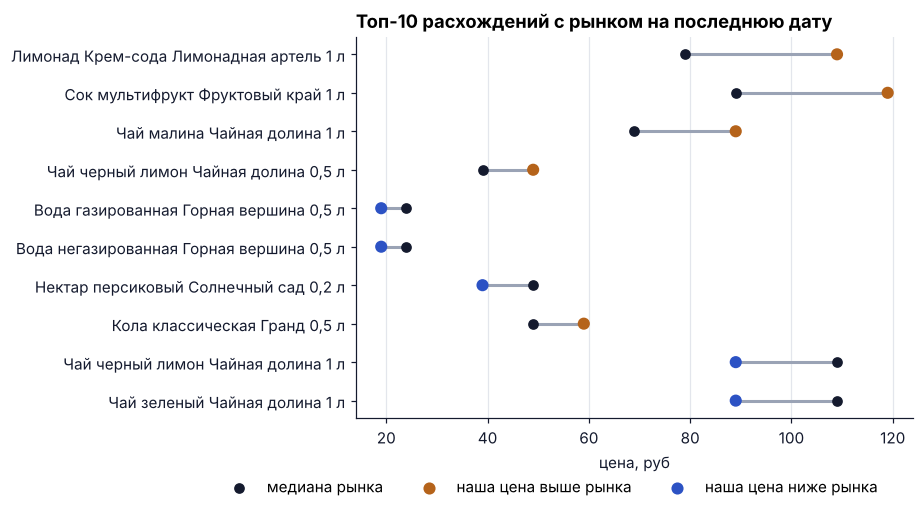

In [9]:
top = alerts.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
y = np.arange(len(top))
ax.hlines(y, top["market_median"], top["own_price"], color=GREY, lw=2)
ax.scatter(top["market_median"], y, color=INK, s=36, label="медиана рынка", zorder=3)
colors = [WARM if t == "дороже рынка" else ACCENT for t in top["alert_type"]]
ax.scatter(top["own_price"], y, color=colors, s=48, label="наша цена", zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([n if len(n) <= 42 else n[:40] + "…" for n in top["name"]])
ax.grid(axis="y", visible=False)
ax.set_xlabel("цена, руб")
ax.set_title("Топ-10 расхождений с рынком на последнюю дату")
ax.scatter([], [], color=WARM, s=48, label="наша цена выше рынка")
ax.scatter([], [], color=ACCENT, s=48, label="наша цена ниже рынка")
handles, labels = ax.get_legend_handles_labels()
keep = [i for i, l in enumerate(labels) if l != "наша цена"]
ax.legend([handles[i] for i in keep], [labels[i] for i in keep], frameon=False, ncol=3,
          loc="upper center", bbox_to_anchor=(0.35, -0.12))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_top_alerts.png")
plt.show()

In [10]:
up = alerts[alerts["alert_type"] == "дешевле рынка"]
down = alerts[alerts["alert_type"] == "дороже рынка"]
print(f"Можно поднять цену на {len(up)} SKU: в среднем на {(up['рекомендованная'] / up['own_price'] - 1).mean():.1%}")
print(f"Стоит пересмотреть цену на {len(down)} SKU, из них {(down['note'] != '').sum()} упираются в минимальную маржу 25%")
print(f"Из них цену нельзя снизить вовсе (рекомендованная равна текущей): {(down['рекомендованная'] >= down['own_price']).sum()}")

Можно поднять цену на 14 SKU: в среднем на 16.6%
Стоит пересмотреть цену на 7 SKU, из них 6 упираются в минимальную маржу 25%
Из них цену нельзя снизить вовсе (рекомендованная равна текущей): 4


## 5. Динамика за две недели

Колебания рынка: промо на отдельных площадках и плавные изменения цен. Наша цена в демо-данных не меняется, поэтому индекс двигается вслед за рынком.

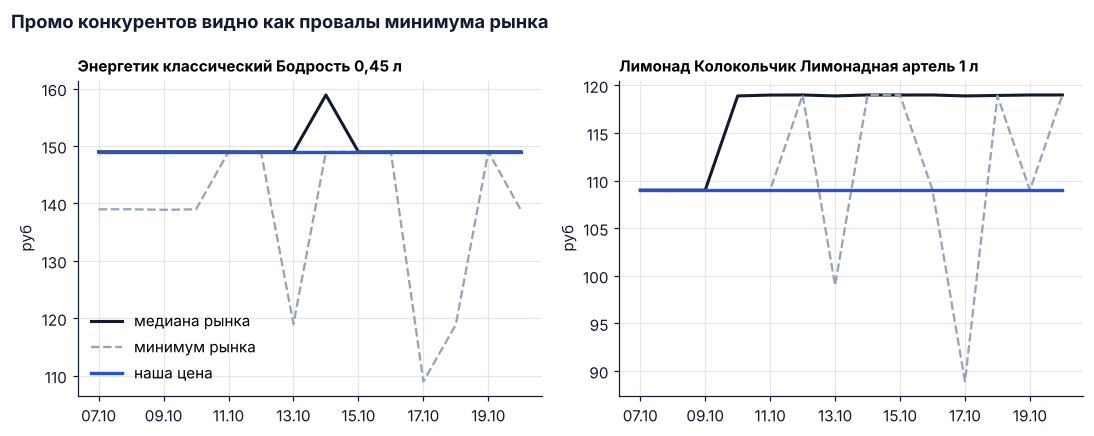

In [11]:
hist = con.execute("SELECT * FROM mart.price_history ORDER BY snapshot_date").df()
for c in ["own_price", "market_min", "market_median", "price_index"]:
    hist[c] = hist[c].astype(float)
# SKU с ценой от 80 руб, где рынок покрыт хотя бы двумя площадками и минимум заметно проседает (промо)
stats = hist.assign(gap=1 - hist["market_min"] / hist["market_median"]).groupby("sku_id").agg(
    own=("own_price", "first"), gap=("gap", "max"))
picks = list(stats[stats["own"] >= 80].sort_values("gap", ascending=False).index[:2])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, sku in zip(axes, picks):
    h = hist[hist["sku_id"] == sku]
    ax.plot(h["snapshot_date"], h["market_median"], color=INK, lw=2, label="медиана рынка")
    ax.plot(h["snapshot_date"], h["market_min"], color=GREY, lw=1.5, ls="--", label="минимум рынка")
    ax.plot(h["snapshot_date"], h["own_price"], color=ACCENT, lw=2.2, label="наша цена")
    ax.set_title(h["name"].iloc[0], fontsize=10)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d.%m"))
    ax.set_ylabel("руб")
axes[0].legend(frameon=False, loc="best")
fig.suptitle("Промо конкурентов видно как провалы минимума рынка", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_price_dynamics.png")
plt.show()

In [12]:
daily = con.execute("""SELECT snapshot_date,
       AVG(CASE WHEN positioning = 'дороже рынка' THEN 1.0 ELSE 0 END) AS доля_дороже,
       AVG(CASE WHEN positioning = 'дешевле рынка' THEN 1.0 ELSE 0 END) AS доля_дешевле
FROM mart.price_index GROUP BY 1 ORDER BY 1""").df()
daily.set_index("snapshot_date").round(3)

,доля_дороже,доля_дешевле
snapshot_date,,
2026-10-07,0.224,0.355
2026-10-08,0.145,0.408
2026-10-09,0.197,0.408
2026-10-10,0.200,0.427
2026-10-11,0.173,0.387
2026-10-12,0.158,0.408
2026-10-13,0.211,0.368
2026-10-14,0.171,0.368
2026-10-15,0.145,0.368


## Выводы

* Пайплайн собирает предложения трёх площадок с разными форматами ответов, отсеивает дубли и битые цены и сопоставляет позиции с матрицей без ложных склеек (точность и полнота в таблице раздела 2).
* На последнюю дату большая часть SKU в рынке. Алерты делятся на две группы: где цену можно поднять до рынка без потери продаж и где мы заметно дороже рынка.
* Часть позиций «дороже рынка» нельзя опустить до медианы: мешает минимальная маржа. Это сигнал для переговоров о закупочной цене, а не для снижения розницы.
* Все цифры пересчитываются ежедневно и попадают в Excel-отчёт категорийного менеджера.

In [13]:
con.close()